# 15 — Min / max price: model comparison, forecast and dashboard

*Extension: min / max price · code: `run_range_models.py`, `dashboard/app.py`*

Puts XGBoost (12), CatBoost (13) and the LSTM (14) side by side with the two baselines and their ensemble, then trains the final models on all data, makes today's forecast and writes every file the dashboard reads.

← previous: [`14_lstm.ipynb`](14_lstm.ipynb)

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]   # project package + root scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 10})

In [2]:
import json
import run_range_models as rrm
from sp500.config import DATA_PROCESSED, REPORTS
from sp500.range_data import load_range_table, feature_columns
from sp500.range_models import MODEL_NAMES, MODELS

table = load_range_table()
feats = feature_columns(table)

## 1. Collect out-of-sample predictions

ML predictions come from notebooks 12–14 (re-computed here if missing); the baselines are cheap and run here.

In [3]:
parts = []
for m in ("xgboost", "catboost", "lstm"):
    path = DATA_PROCESSED / f"range_pred_{m}.parquet"
    parts.append(pd.read_parquet(path) if path.exists() else rrm.run_validation(table, feats, [m], log=lambda *a: None))
parts.append(rrm.run_validation(table, feats, ["hist_quantile", "vol_band"], log=lambda *a: None))
pred = rrm.add_ensemble(pd.concat(parts, ignore_index=True))
pred.to_parquet(DATA_PROCESSED / "range_predictions.parquet")
pred.groupby(["split", "model"]).size().unstack(0)

split,holdout,walk_forward
model,,
catboost,4828,22144
ensemble,4776,22144
hist_quantile,4828,22144
lstm,4828,22144
vol_band,4828,22144
xgboost,4828,22144


## 2. Scores

In [4]:
m = rrm.metrics(pred)
m.to_csv(REPORTS / "range_results.csv", index=False)
rrm.write_report(m, REPORTS / "range_results.md", runtime=0)
order = ["ensemble", "xgboost", "catboost", "lstm", "vol_band", "hist_quantile"]
t = m.pivot_table(index="model", columns=["split", "h", "target"], values="pinball_x100").reindex(order)
t.index = t.index.map(MODEL_NAMES)
t.style.format("{:.3f}").highlight_min(axis=0, color="#d7e8fb")

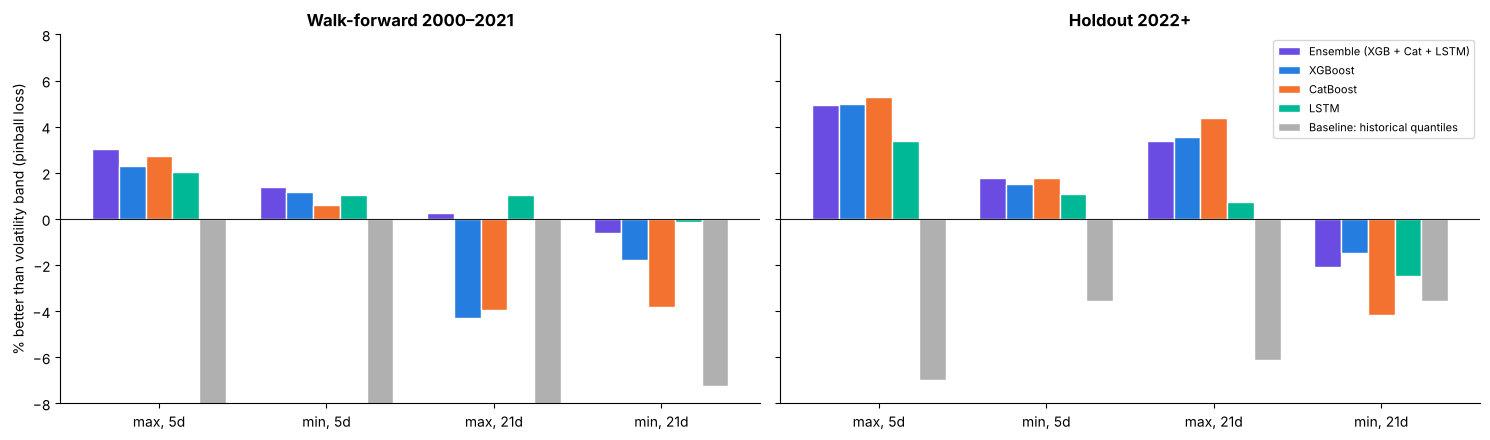

historical-quantiles baseline is clipped at -8% (it loses by 5-16%)


In [5]:
colors = {"ensemble": "#6a4ce2", "xgboost": "#257de0", "catboost": "#f47230", "lstm": "#00b894", "hist_quantile": "#b0b0b0"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, split in zip(axes, ("walk_forward", "holdout")):
    g = m[m.split == split].copy()
    ref = g[g.model == "vol_band"].set_index(["h", "target"])["pinball_x100"]
    g["gain"] = (1 - g["pinball_x100"] / g.set_index(["h", "target"]).index.map(ref)) * 100
    keys = [(5, "up"), (5, "down"), (21, "up"), (21, "down")]
    x = np.arange(len(keys)); w = 0.16
    for i, mod in enumerate(["ensemble", "xgboost", "catboost", "lstm", "hist_quantile"]):
        vals = [g[(g.model == mod) & (g.h == h) & (g.target == tg)]["gain"].iloc[0] for h, tg in keys]
        ax.bar(x + (i - 2) * w, vals, w, label=MODEL_NAMES[mod], color=colors[mod], edgecolor="white")
    ax.set_xticks(x, [f"{'max' if tg == 'up' else 'min'}, {h}d" for h, tg in keys])
    ax.axhline(0, color="#191919", lw=0.8); ax.set_ylim(-8, 8)
    ax.set_title("Walk-forward 2000–2021" if split == "walk_forward" else "Holdout 2022+")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("% better than volatility band (pinball loss)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("historical-quantiles baseline is clipped at -8% (it loses by 5-16%)")

## 3. Final models and today's forecast

Every model is retrained on all data with a known target and forecasts from the last close.

In [6]:
forecast, imps = rrm.final_forecast(table, feats, list(MODELS))
(DATA_PROCESSED / "range_forecast.json").write_text(json.dumps(forecast, indent=2))
imps.to_csv(REPORTS / "range_feature_importance.csv", index=False)
rrm.pattern_stats_table(table).to_csv(REPORTS / "range_pattern_stats.csv", index=False)

close = forecast["close"]
rows = []
for h, d in forecast["horizons"].items():
    for mod in order:
        u, dn = d[mod]["up"], d[mod]["down"]
        rows.append({"horizon": f"next {h} days", "model": MODEL_NAMES[mod],
                     "min (10%)": close * np.exp(dn[0]), "min (median)": close * np.exp(dn[1]),
                     "max (median)": close * np.exp(u[1]), "max (90%)": close * np.exp(u[2])})
print(f"Forecast made at the close of {forecast['as_of']} (S&P 500 = {close:,.0f})")
pd.DataFrame(rows).set_index(["horizon", "model"]).style.format("{:,.0f}")

Forecast made at the close of 2026-10-23 (S&P 500 = 7,624)


## 4. Dashboard

All dashboard inputs are now in `data/processed/` and `reports/`. Launch it from the repo root:

```bash
streamlit run dashboard/app.py
```

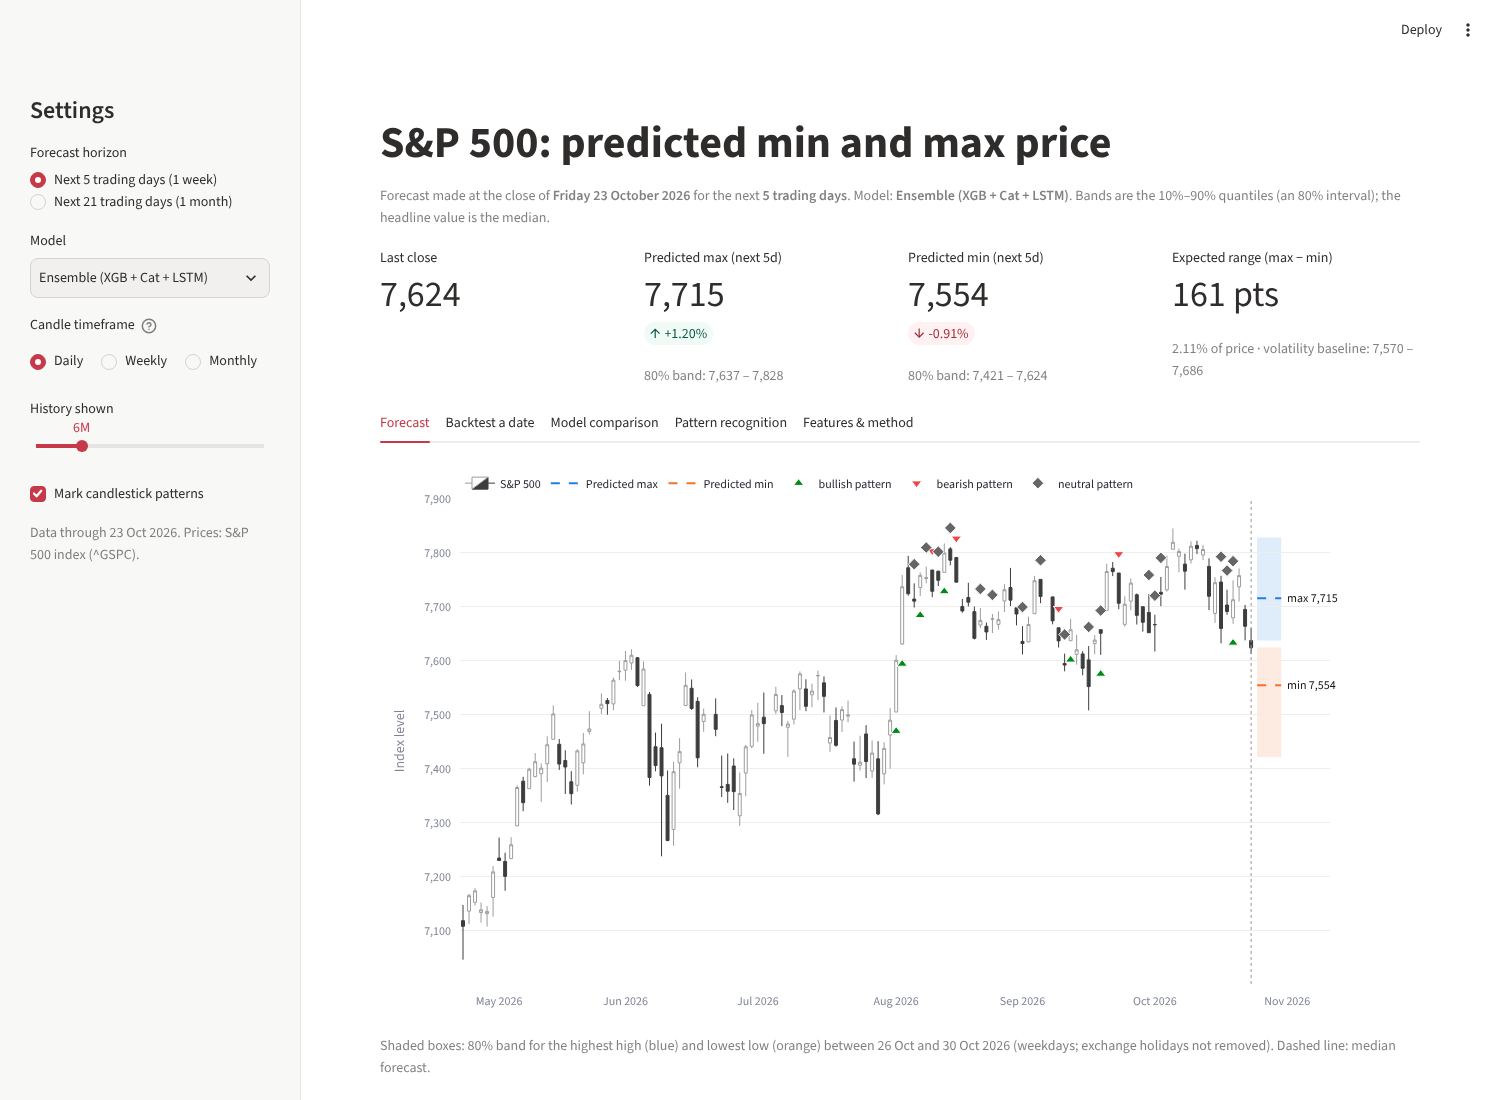

In [7]:
display(Image(ROOT / "docs" / "figures" / "dashboard_forecast.png", width=900))

## Conclusions

- **Next-week range:** every ML model beats both baselines for the max *and* the min, in walk-forward and on the holdout, by a small but consistent margin. Median error on the max ≈ 0.93% of price (~70 points).
- **Next-month max:** boosting (CatBoost, XGBoost) is clearly better on the holdout (≈ +5% skill).
- **Next-month min:** nothing beats the volatility band; large falls come from shocks (2020, April 2025) no feature anticipates, consistent with the regime result that bear-market *starts* are unpredictable.
- **Most of the skill is volatility.** Patterns and multi-timeframe candles add a little on top.
- **Bands for the min are too narrow** (≈ 70% coverage instead of 80%): conformal calibration is the natural next step.